# Supplementary Figure 1: annotation versus RCTD cell-type distributions

Paired 100% stacked bars compare the **used annotation** and **RCTD primary cell type on exactly the same RCTD-singlet cells**, pooling all included slices per dataset. Each dataset is an x-axis group with Used/RCTD bars. This is a cell-weighted distribution: larger slices contribute more cells. No expression matrices, cleaning, expression QC, or additional inference are required.

Used labels: Aging brain `cell_type` (regenerated donor 5–8 results), Brain MERFISH `class`, NSCLC CosMx `cell_type_harmonized`, Breast Xenium `harmony_cell_type`. Other RCTD classes (doublets/rejects/filtered) are excluded from both bars. Brain MERFISH singlets with a missing `class` label are excluded from both distributions and the agreement calculation. For the other datasets, missing labels are audited and retained as gray Unannotated segments; the two bars always use the same cells.

Color shades group related types. Breast colors come directly from the Xenium UMAP palette. The other three UMAP notebooks currently use generic categorical palettes; their existing slice-morphology notebooks define the family-shaded palettes used here. RCTD-only types retain their family's hue without changing the used types' existing colors. Colors and provenance are exported.


In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

ROOT = Path("/work/magroup/skrieger/Syndri/data/datasets")
PROJECT = Path("/home/jwinchel/Syndri")
DATASETS = {
    # "agingbrain_merfish": {
    #     "title": "Aging brain MERFISH", "annotation_key": "cell_type",
    #     "annotation_dir": ROOT / "agingbrain_merfish/results/model_runs/10x_agingbrain_donors5to8_m87_regenerated_rctd_20261010",
    #     "rctd_dir": ROOT / "agingbrain_merfish/results/spatial", "glob": "*.h5ad",
    #     "palette_kind": "family_morphology",
    #     "palette_notebook": PROJECT / "data/agingbrain_merfish/AgingBrainMERFISHSliceMorphology.ipynb",
    # },
    "brain_merfish": {
        "title": "Brain MERFISH", "annotation_key": "class",
        "annotation_dir": ROOT / "brain_merfish/results/final",
        "rctd_dir": ROOT / "brain_merfish/results/spatial", "glob": "*.h5ad",
        "palette_kind": "family_morphology",
        "palette_notebook": PROJECT / "data/brain_merfish/BrainMERFISHSliceMorphology.ipynb",
    },
    "nsclc_cosmx": {
        "title": "NSCLC CosMx", "annotation_key": "cell_type_harmonized",
        "annotation_dir": ROOT / "nsclc_cosmx/results/final",
        "rctd_dir": ROOT / "nsclc_cosmx/results/spatial", "glob": "*.h5ad",
        "palette_kind": "family_morphology",
        "palette_notebook": PROJECT / "data/nsclc_cosmx/CosMxSliceMorphology.ipynb",
    },
    "breast_xenium": {
        "title": "Breast Xenium", "annotation_key": "harmony_cell_type",
        "annotation_dir": ROOT / "breast_xenium/results/final",
        "rctd_dir": None, "glob": "*_rctd_annotated.h5ad",
        "palette_kind": "xenium_umap",
        "palette_notebook": PROJECT / "figures/Figure2_UMAPs_Xenium.ipynb",
    },
}
METHODS = ["Used annotation", "RCTD primary"]
OUTPUT_DIR = PROJECT / "figures/outputs" / ("SuppFig1_RCTD_" + datetime.now(ZoneInfo("America/New_York")).strftime("%Y%m%d_%H%M%S_%f"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Output directory:", OUTPUT_DIR)


Output directory: /home/jwinchel/Syndri/figures/outputs/SuppFig1_RCTD_20261104_184358_200075


## Read metadata and select a shared singlet cohort

For Xenium, use `obs.rctd_spot_class == "singlet"` and `obs.rctd_first_type`. For the other datasets, decode `uns.rctd_postprocessing_X`: the installed RCTD package defines spot-class **1 as singlet**, and `first_type` is a zero-based index into `cell_type_names`. Align calls to the used AnnData by exact observation ID. If postprocessing was filtered, accept an alignment only when the padded RCTD weight mask exactly recovers the stored array length. Raise an error rather than guess a mapping.

For Brain MERFISH, RCTD-singlet cells with a missing or unassigned used `class` label are dropped before either bar and the label-agreement calculation. For the other datasets, empty/unassigned labels remain as a gray Unannotated segment. The unresolved aging-brain annotation `cell` is retained and shown in gray. Slice provenance, total/singlet/matched counts, dropped-label counts, and label agreement are saved. Labels remain at each dataset's existing annotation granularity.


In [2]:
"""Read annotation metadata only and compare distributions on paired RCTD singlets."""
from pathlib import Path
import ast,json
from collections import Counter
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex


def read_column(node):
    if isinstance(node,h5py.Group):
        if 'codes' in node and 'categories' in node:
            categories=read_column(node['categories']);codes=node['codes'][:]
            out=np.full(len(codes),None,dtype=object);valid=codes>=0;out[valid]=categories[codes[valid]];return out
        if 'values' in node and 'mask' in node:
            out=np.asarray(read_column(node['values']),dtype=object);out[node['mask'][:]]=None;return out
        raise ValueError('Unsupported metadata encoding: '+node.name)
    return node.asstr()[:] if node.dtype.kind in 'OSU' else node[:]


def index_from_file(f):
    ids=pd.Index(read_column(f['obs'][f['obs'].attrs['_index']]).astype(str))
    if ids.has_duplicates:raise ValueError('Duplicate cell IDs: '+str(f.filename))
    return ids


def valid_label(values):
    s=pd.Series(values,dtype='string').str.strip()
    return (s.notna() & ~s.str.lower().isin(['','nan','none','<na>','unassigned'])).to_numpy(dtype=bool,na_value=False)


def rctd_calls(path):
    with h5py.File(path) as f:
        ids=index_from_file(f)
        if 'rctd_spot_class' in f['obs'] and 'rctd_first_type' in f['obs']:
            calls=pd.DataFrame(dict(spot_class=read_column(f['obs/rctd_spot_class']),primary=read_column(f['obs/rctd_first_type'])),index=ids)
            calls['singlet']=calls.spot_class.astype('string').str.lower().eq('singlet').fillna(False)
            storage='obs/rctd_spot_class + obs/rctd_first_type'
        else:
            group=f['uns/rctd_postprocessing_X'];status=np.asarray(group['spot_class'][:]);first=np.asarray(group['first_type'][:]);names=read_column(group['cell_type_names'])
            if len(status)!=len(first):raise ValueError('RCTD array lengths differ')
            if len(status)==len(ids):target=ids
            else:
                # The annotation script pads weights but can retain unpadded postprocessing arrays.
                weights=f['obsm/rctd_weights_X'][:];mask=np.isfinite(weights).any(axis=1)&(np.nan_to_num(weights).sum(axis=1)>0)
                if len(weights)!=len(ids) or mask.sum()!=len(status):raise ValueError('Cannot align filtered RCTD calls to cell IDs: '+str(path))
                target=ids[mask]
            primary=np.full(len(first),None,dtype=object);ok=(first>=0)&(first<len(names));primary[ok]=names[first[ok].astype(int)]
            # rctd/_types.py: 0=reject, 1=singlet, 2=doublet_certain, 3=doublet_uncertain.
            if not set(np.unique(status)).issubset({0,1,2,3}):raise ValueError('Unknown RCTD spot-class code')
            calls=pd.DataFrame(dict(spot_class=status,primary=primary,singlet=status==1),index=target).reindex(ids)
            calls['singlet']=calls.singlet.eq(True)
            storage='uns/rctd_postprocessing_X (singlet=1; zero-based first_type)'
    return calls,storage


def load_compositions(datasets):
    counts=[];audits=[];observed={}
    for dataset,config in datasets.items():
        paths=sorted(Path(config['annotation_dir']).glob(config['glob']))
        if not paths:raise FileNotFoundError(config['annotation_dir'])
        observed[dataset]=set()
        for path in paths:
            with h5py.File(path) as f:
                ids=index_from_file(f);labels=pd.Series(read_column(f['obs'][config['annotation_key']]),index=ids,dtype='string').str.strip()
            if len(ids)!=len(labels):raise ValueError('Annotation length mismatch')
            observed[dataset].update(labels.loc[valid_label(labels)].astype(str))
            rctd_path=path if config['rctd_dir'] is None else Path(config['rctd_dir'])/path.name
            if not rctd_path.exists():raise FileNotFoundError(rctd_path)
            calls,storage=rctd_calls(rctd_path);paired=calls.reindex(ids)
            singlet=paired.singlet.eq(True).to_numpy()
            used_ok=valid_label(labels);rctd_ok=valid_label(paired.primary)
            # Brain MERFISH cells without a used `class` annotation are
            # omitted from both paired distributions and agreement.
            valid=singlet & (used_ok if dataset=='brain_merfish' else np.ones(len(ids),dtype=bool))
            used_plot=labels.to_numpy(dtype=object).copy();used_plot[~used_ok]='Unannotated'
            rctd_plot=paired.primary.to_numpy(dtype=object).copy();rctd_plot[~rctd_ok]='Unannotated'
            n=int(valid.sum())
            for method,values in [('Used annotation',used_plot[valid]),('RCTD primary',rctd_plot[valid])]:
                pertype=Counter(str(x).strip() for x in values)
                assert sum(pertype.values())==n
                counts.extend(dict(dataset=dataset,slice=path.stem,method=method,cell_type=typ,n_cells=num) for typ,num in pertype.items())
            audits.append(dict(dataset=dataset,slice=path.stem,annotation_file=str(path),rctd_file=str(rctd_path),annotation_key=config['annotation_key'],rctd_storage=storage,
                n_annotation_cells=len(ids),n_rctd_cells=len(calls),n_rctd_matched_ids=int(ids.isin(calls.index).sum()),n_rctd_singlets=int(singlet.sum()),n_singlets_dropped_missing_used_label=int((singlet & ~used_ok).sum()) if dataset=='brain_merfish' else 0,n_paired_singlets=n,
                n_singlets_missing_either_label=int((singlet & ~(used_ok & rctd_ok)).sum()),n_singlets_missing_used_label=int((singlet & ~used_ok).sum()),n_singlets_missing_rctd_label=int((singlet & ~rctd_ok).sum()),n_rctd_singlets_not_in_annotation=int((calls.singlet & ~calls.index.isin(ids)).sum()),
                paired_label_agreement=float(np.mean(used_plot[valid & used_ok & rctd_ok]==rctd_plot[valid & used_ok & rctd_ok])) if (valid & used_ok & rctd_ok).any() else np.nan))
            print(dataset,path.stem,'paired singlets:',n,flush=True)
    per_slice=pd.DataFrame(counts);audit=pd.DataFrame(audits)
    total=per_slice.groupby(['dataset','method','cell_type'],observed=True).n_cells.sum().reset_index()
    total['denominator']=total.groupby(['dataset','method']).n_cells.transform('sum')
    total['fraction']=total.n_cells/total.denominator
    sums=total.groupby(['dataset','method']).fraction.sum();assert np.allclose(sums,1)
    for dataset,group in total.groupby('dataset'):
        assert group.groupby('method').n_cells.sum().nunique()==1
    return total,per_slice,audit,observed


def make_palettes(datasets,counts,observed):
    palette={};order={};table=[]
    for dataset,config in datasets.items():
        path=Path(config['palette_notebook']);notebook=json.loads(path.read_text());base=set(observed[dataset]);union=base|set(counts.loc[counts.dataset.eq(dataset),'cell_type'])
        if config['palette_kind']=='xenium_umap':
            source=next(''.join(c['source']) for c in notebook['cells'] if c['cell_type']=='code' and 'palette_dict = dict(zip(cell_type_order, palette))' in ''.join(c['source']))
            # Execute only the inspected standalone palette-definition cell, never UMAP/data cells.
            env={};exec(compile(source,str(path)+':palette','exec'),env)
            colors={k:to_hex(v) for k,v in env['palette_dict'].items()};types=env['cell_type_order']
            groups=[('Lymphoid','Blues',types[:5]),('Myeloid / innate','Reds',types[5:9]),('Stromal / vascular','Greens',types[9:14]),('Malignant','Purples',types[14:])]
        else:
            groups=None
            for c in notebook['cells']:
                if c['cell_type']!='code':continue
                for node in ast.parse(''.join(c['source'])).body:
                    if isinstance(node,ast.Assign) and any(isinstance(t,ast.Name) and t.id=='CELL_TYPE_FAMILIES' for t in node.targets):groups=ast.literal_eval(node.value)
            if groups is None:raise ValueError('No grouped family palette in '+str(path))
            colors={}
        final_order=[];families={};provenance={}
        for family,cmap,labels in groups:
            if labels is None:
                suffix=' Glut' if family=='Glutamatergic neurons' else ' GABA'
                base_labels=sorted(c for c in base if c.endswith(suffix));extras=sorted(c for c in union-base if c.endswith(suffix))
            else:
                base_labels=[c for c in labels if c in base];extras=[c for c in labels if c in union and c not in base_labels]
            if config['palette_kind']!='xenium_umap':
                for label,color in zip(base_labels,plt.get_cmap(cmap)(np.linspace(.4,.88,len(base_labels)))):colors[label]=to_hex(color)
                for label,color in zip(extras,plt.get_cmap(cmap)(np.linspace(.25,.95,len(extras)+2)[1:-1])):colors[label]=to_hex(color)
            for label in base_labels+extras:
                final_order.append(label);families[label]=family;provenance[label]='reference palette' if label in base else 'same-family extension for RCTD-only type'
        extra=sorted(union-set(final_order))
        for label,color in zip(extra,plt.get_cmap('Greys')(np.linspace(.4,.88,len(extra)))):
            colors[label]=to_hex(color);families[label]='Unannotated' if label=='Unannotated' else 'Other / unmapped';provenance[label]='missing label shown in gray' if label=='Unannotated' else 'unmapped gray';final_order.append(label)
        assert len(final_order)==len(set(final_order))
        palette[dataset]=colors;order[dataset]=[c for c in final_order if c in set(counts.loc[counts.dataset.eq(dataset),'cell_type'])]
        for label in final_order:
            table.append(dict(dataset=dataset,cell_type=label,family=families[label],color=colors[label],palette_notebook=str(path),provenance=provenance[label]))
    return palette,order,pd.DataFrame(table)


In [3]:
composition, slice_composition, coverage, observed_types = load_compositions(DATASETS)
palettes, cell_type_orders, palette_table = make_palettes(DATASETS, composition, observed_types)
composition.to_csv(OUTPUT_DIR / "cell_type_composition.csv", index=False)
slice_composition.to_csv(OUTPUT_DIR / "slice_cell_type_counts.csv", index=False)
coverage.to_csv(OUTPUT_DIR / "slice_coverage.csv", index=False)
palette_table.to_csv(OUTPUT_DIR / "cell_type_colors.csv", index=False)
(OUTPUT_DIR / "dataset_config.json").write_text(json.dumps(DATASETS, default=str, indent=2) + "\n")
summary = coverage.groupby("dataset", sort=False).agg(
    n_slices=("slice", "nunique"), n_annotation_cells=("n_annotation_cells", "sum"),
    n_rctd_singlets=("n_rctd_singlets", "sum"), n_paired_singlets=("n_paired_singlets", "sum"),
    n_singlets_missing_either_label=("n_singlets_missing_either_label", "sum"))
summary.to_csv(OUTPUT_DIR / "dataset_coverage.csv")
display(summary)


brain_merfish st_integrated_slice-Zhuang-ABCA-4.001 paired singlets: 45583
brain_merfish st_integrated_slice-Zhuang-ABCA-4.002 paired singlets: 52417
brain_merfish st_integrated_slice-Zhuang-ABCA-4.003 paired singlets: 71016
nsclc_cosmx st_integrated_slice-Lung12 paired singlets: 11566
nsclc_cosmx st_integrated_slice-Lung13 paired singlets: 23539
nsclc_cosmx st_integrated_slice-Lung5_Rep1 paired singlets: 36321
nsclc_cosmx st_integrated_slice-Lung5_Rep2 paired singlets: 26480
nsclc_cosmx st_integrated_slice-Lung5_Rep3 paired singlets: 39039
nsclc_cosmx st_integrated_slice-Lung6 paired singlets: 73322
nsclc_cosmx st_integrated_slice-Lung9_Rep1 paired singlets: 31651
nsclc_cosmx st_integrated_slice-Lung9_Rep2 paired singlets: 70500
breast_xenium GSM9509156_breast_breast_B17_B17_rctd_annotated paired singlets: 57175
breast_xenium GSM9509157_breast_breast_B16_B16_rctd_annotated paired singlets: 10234
breast_xenium GSM9509158_breast_breast_B15_B15_rctd_annotated paired singlets: 29518
breas

,n_slices,n_annotation_cells,n_rctd_singlets,n_paired_singlets,n_singlets_missing_either_label
dataset,,,,,
brain_merfish,3,215278,169016,169016,40301
nsclc_cosmx,8,771236,312418,312418,0
breast_xenium,19,1673926,1233787,1233787,0


## Paired stacked distributions

Each pair has the same denominator. Brain MERFISH singlets without a `class` annotation are excluded from both bars; the other datasets retain missing labels as Unannotated. Counts above the bars give the included paired singlet cohort. Both bars use the same exact-type colors and stacking order within a dataset; each legend groups related types into shared hues. The four datasets use their own biological annotation vocabularies, so a color family is interpreted using that dataset's legend.


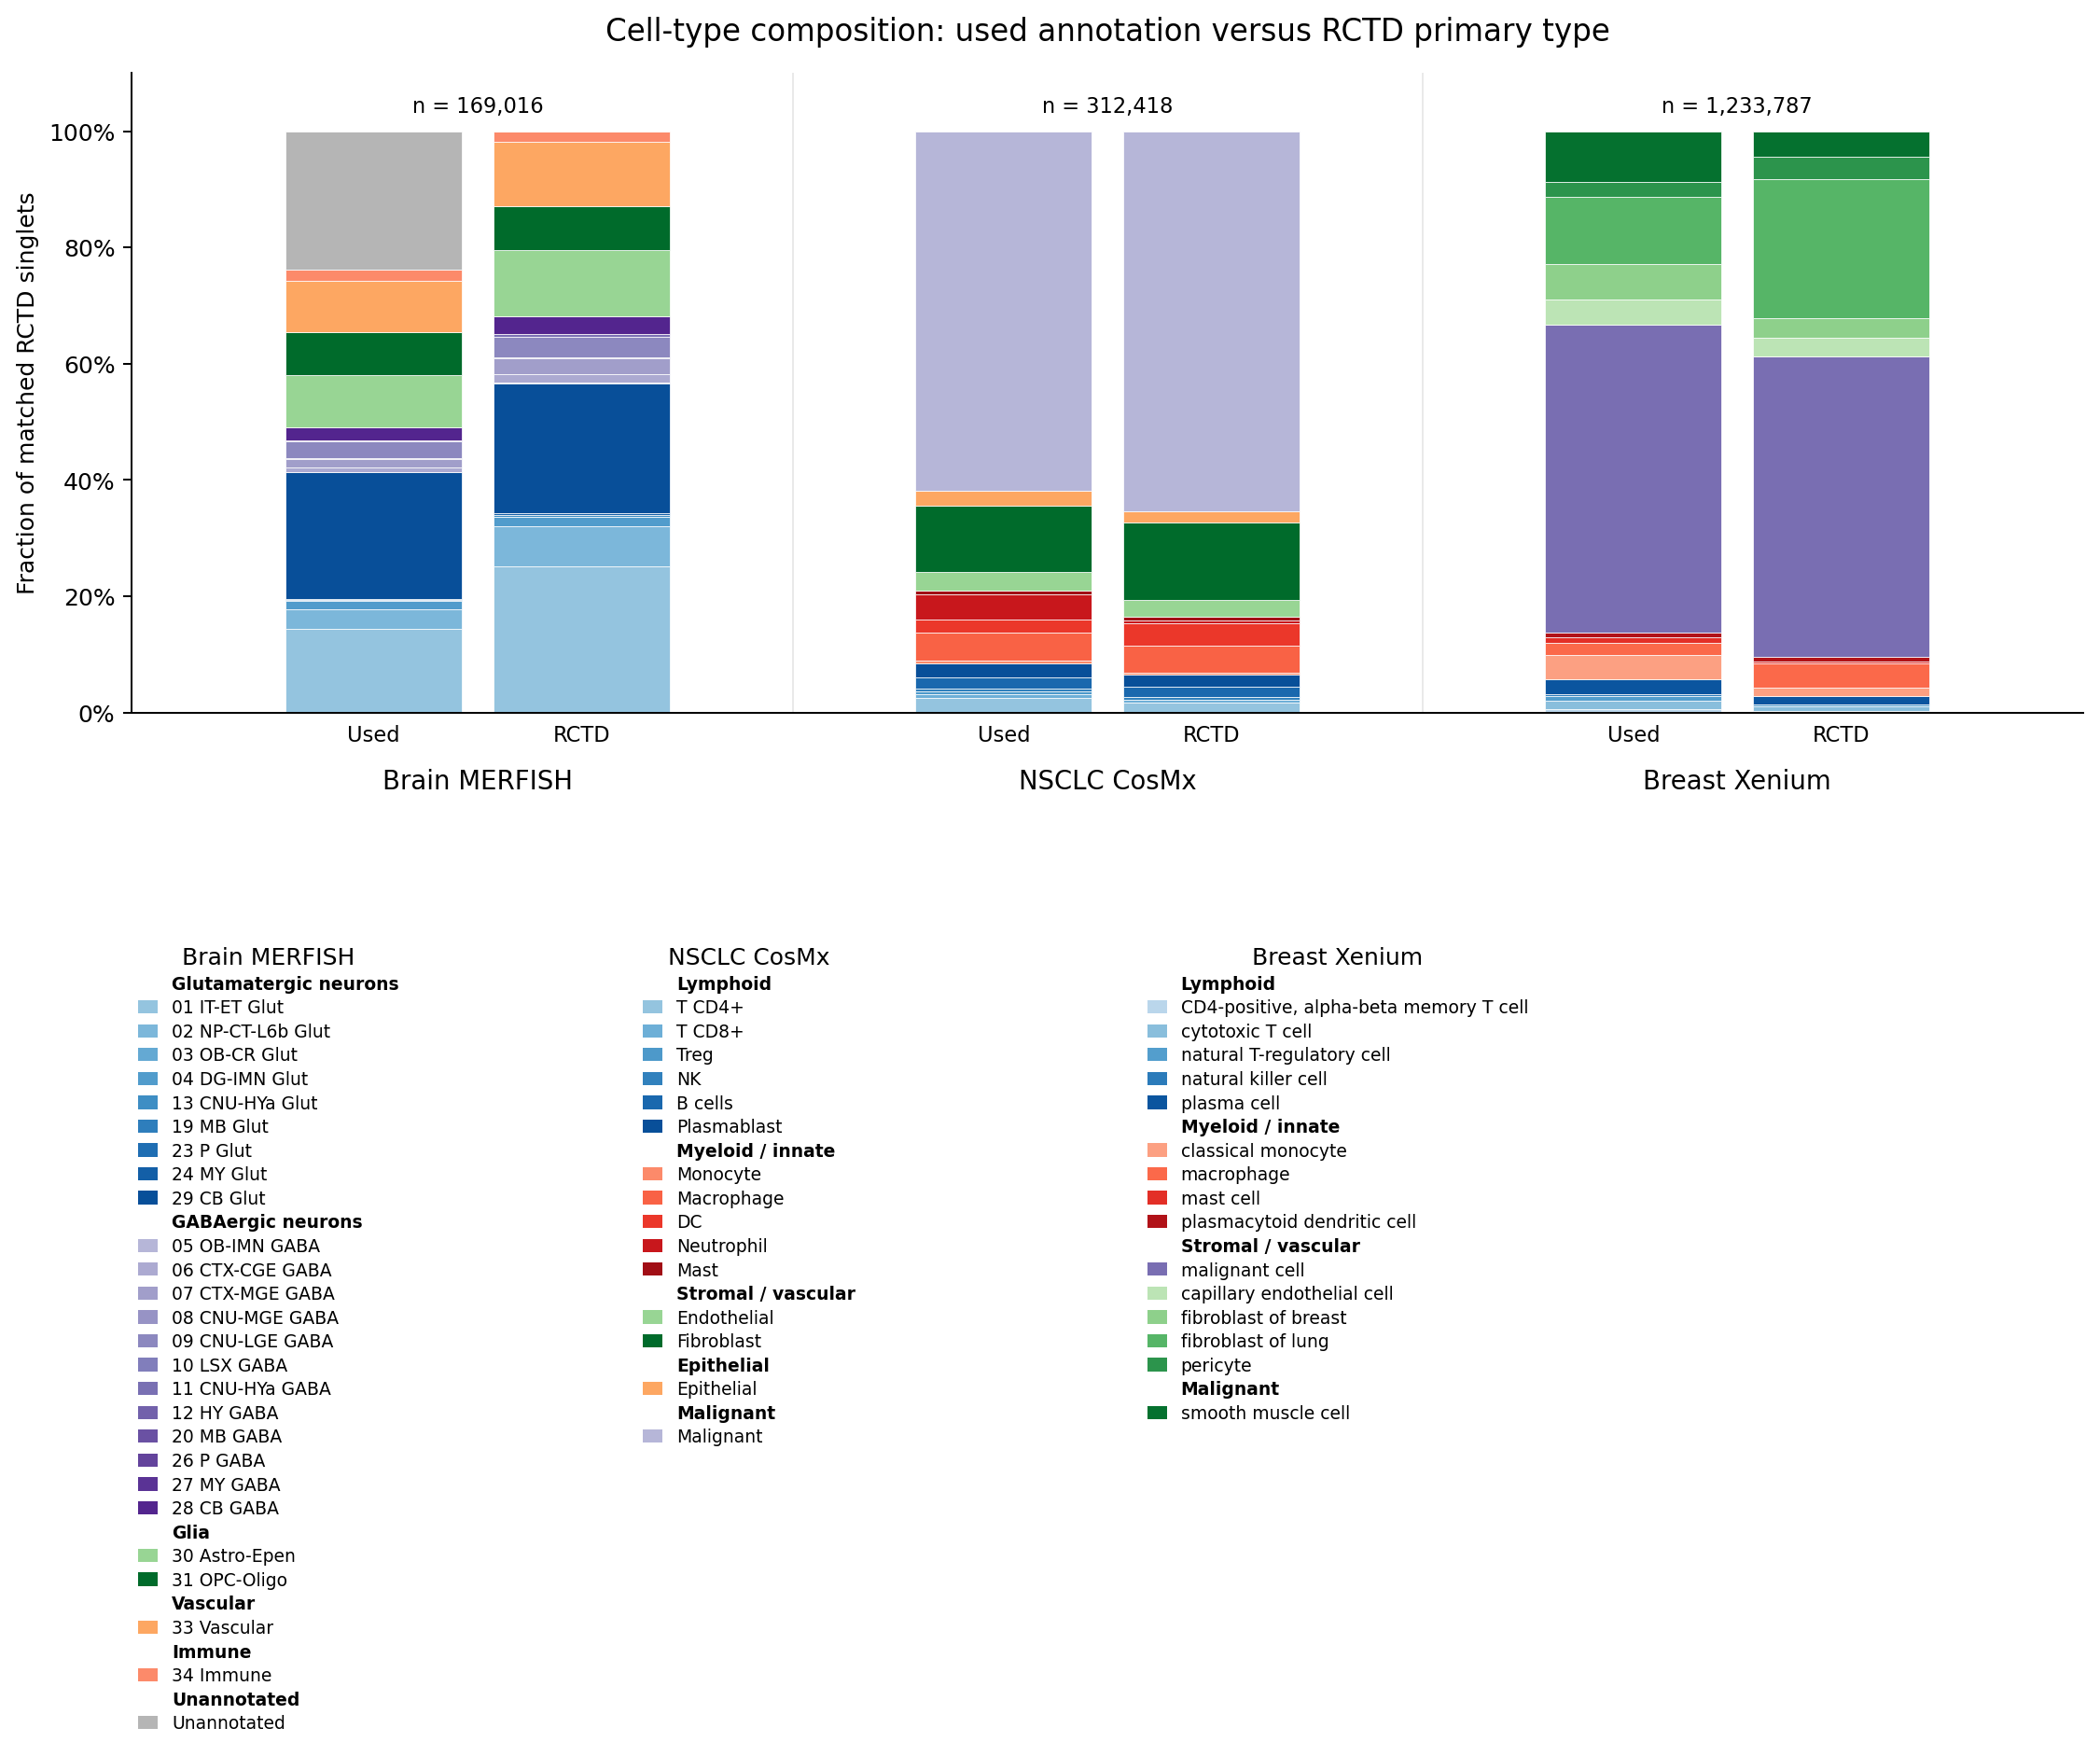

Saved PNG/PDF and supporting tables: /home/jwinchel/Syndri/figures/outputs/SuppFig1_RCTD_20261104_184358_200075


In [4]:
fig = plt.figure(figsize=(15, 11), dpi=180)
grid = fig.add_gridspec(2, 4, height_ratios=[1.15, 1.0], hspace=.38, wspace=.15)
ax = fig.add_subplot(grid[0, :])
width, offset = .28, .165
for xpos, (dataset, config) in enumerate(DATASETS.items()):
    subset = composition.loc[composition.dataset.eq(dataset)]
    for method, shift in zip(METHODS, [-offset, offset]):
        counts = subset.loc[subset.method.eq(method)].set_index("cell_type")
        bottom = 0.0
        for typ in cell_type_orders[dataset]:
            value = float(counts.loc[typ, "fraction"]) if typ in counts.index else 0.0
            ax.bar(xpos + shift, value, width=width, bottom=bottom,
                   color=palettes[dataset][typ], edgecolor="white", linewidth=.3)
            bottom += value
        assert np.isclose(bottom, 1)
    n = int(summary.loc[dataset, "n_paired_singlets"])
    ax.text(xpos, 1.025, f"n = {n:,}", ha="center", va="bottom", fontsize=9)
    if xpos:
        ax.axvline(xpos - .5, color=".9", lw=.7, zorder=0)
ax.set_xticks(range(len(DATASETS)), [c["title"] for c in DATASETS.values()])
method_positions = [i + shift for i in range(len(DATASETS)) for shift in [-offset, offset]]
ax.set_xticks(method_positions, [m for _ in DATASETS for m in ["Used", "RCTD"]], minor=True)
ax.tick_params(axis="x", which="minor", labelsize=9, length=0, pad=5)
ax.tick_params(axis="x", which="major", labelsize=11, length=0, pad=24)
ax.set_ylim(0, 1.10)
ax.set_xlim(-.55, len(DATASETS) - .45)
ax.set_yticks(np.linspace(0, 1, 6))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Fraction of matched RCTD singlets")
ax.set_title("Cell-type composition: used annotation versus RCTD primary type", fontsize=13, pad=14)
ax.spines[["top", "right"]].set_visible(False)

for column, (dataset, config) in enumerate(DATASETS.items()):
    legend_ax = fig.add_subplot(grid[1, column])
    legend_ax.axis("off")
    color_rows = palette_table.loc[palette_table.dataset.eq(dataset)].set_index("cell_type")
    handles, header_indices = [], []
    previous_family = None
    for typ in cell_type_orders[dataset]:
        family = color_rows.loc[typ, "family"]
        if family != previous_family:
            header_indices.append(len(handles))
            handles.append(Patch(facecolor="none", edgecolor="none", label=family))
            previous_family = family
        handles.append(Patch(facecolor=palettes[dataset][typ], edgecolor="none", label=typ))
    legend = legend_ax.legend(handles=handles, loc="upper left", title=config["title"],
                             frameon=False, fontsize=7.5, title_fontsize=10,
                             handlelength=1.1, handleheight=.8, labelspacing=.35, borderaxespad=0)
    for idx in header_indices:
        legend.get_texts()[idx].set_fontweight("bold")
fig.savefig(OUTPUT_DIR / "SuppFig1_RCTD_cell_type_distributions.png", dpi=300, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "SuppFig1_RCTD_cell_type_distributions.pdf", bbox_inches="tight")
plt.show()
print("Saved PNG/PDF and supporting tables:", OUTPUT_DIR)


## Slice and palette audit

Inspect these tables if a distribution differs strongly. Differences can reflect disagreement between annotation methods or reference support; the figure does not measure annotation accuracy against ground truth. RCTD-only labels and their color extensions are explicitly listed in the palette table.


In [5]:
display(coverage)
display(palette_table)


,dataset,slice,annotation_file,rctd_file,annotation_key,rctd_storage,n_annotation_cells,n_rctd_cells,n_rctd_matched_ids,n_rctd_singlets,n_paired_singlets,n_singlets_missing_either_label,n_singlets_missing_used_label,n_singlets_missing_rctd_label,n_rctd_singlets_not_in_annotation,paired_label_agreement
0,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_0,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,10744,10744,10744,5815,5815,0,0,0,0,0.857782
1,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_1,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,9644,9644,9644,5459,5459,0,0,0,0,0.825243
2,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_5_2,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,8983,8983,8983,4831,4831,0,0,0,0,0.832954
3,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_0,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,9462,9462,9462,5052,5052,0,0,0,0,0.974070
4,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_1,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,8164,8164,8164,4398,4398,0,0,0,0,0.973624
5,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_6_2,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,8281,8281,8281,4380,4380,0,0,0,0,0.970320
6,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_7_0,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,10785,10785,10785,4936,4936,0,0,0,0,0.959481
7,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_7_1,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,10609,10609,10609,5185,5185,0,0,0,0,0.967985
8,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_7_2,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,11398,11398,11398,5283,5283,0,0,0,0,0.965550
9,agingbrain_merfish,st_integrated_MsBrainAgingSpatialDonor_8_0,/work/magroup/skrieger/Syndri/data/datasets/ag...,/work/magroup/skrieger/Syndri/data/datasets/ag...,cell_type,uns/rctd_postprocessing_X (singlet=1; zero-bas...,14122,14122,14122,5588,5588,0,0,0,0,0.969936


,dataset,cell_type,family,color,palette_notebook,provenance
0,agingbrain_merfish,neuron,Neurons,#94c4df,/home/jwinchel/Syndri/data/agingbrain_merfish/...,reference palette
1,agingbrain_merfish,inhibitory interneuron,Neurons,#3e8ec4,/home/jwinchel/Syndri/data/agingbrain_merfish/...,reference palette
2,agingbrain_merfish,medium spiny neuron,Neurons,#084f99,/home/jwinchel/Syndri/data/agingbrain_merfish/...,reference palette
3,agingbrain_merfish,astrocyte,Glia,#98d594,/home/jwinchel/Syndri/data/agingbrain_merfish/...,reference palette
4,agingbrain_merfish,oligodendrocyte precursor cell,Glia,#3ea75a,/home/jwinchel/Syndri/data/agingbrain_merfish/...,reference palette
...,...,...,...,...,...,...
64,breast_xenium,fibroblast of breast,Stromal / vascular,#8ed08b,/home/jwinchel/Syndri/figures/Figure2_UMAPs_Xe...,reference palette
65,breast_xenium,fibroblast of lung,Stromal / vascular,#56b567,/home/jwinchel/Syndri/figures/Figure2_UMAPs_Xe...,reference palette
66,breast_xenium,pericyte,Stromal / vascular,#2c944c,/home/jwinchel/Syndri/figures/Figure2_UMAPs_Xe...,reference palette
67,breast_xenium,smooth muscle cell,Stromal / vascular,#05712f,/home/jwinchel/Syndri/figures/Figure2_UMAPs_Xe...,reference palette


## Paired label agreement by dataset

Each point is one slice’s fraction of included **RCTD-singlet cells with both labels present** whose used annotation exactly equals the RCTD primary cell type. Brain MERFISH singlets without a used `class` label are excluded before this calculation; missing/unassigned labels in other datasets are excluded from the agreement denominator (and remain gray in the composition plot). `n_agreement_cells` records that denominator for each slice.

Boxes show slice medians and IQRs; whiskers extend to the most extreme values within 1.5 IQR, with all slice values shown as points. Each slice has equal weight in the boxplot, regardless of cell count. This is exact-label concordance at the existing annotation granularity, not accuracy against a ground truth. Its value is conditional on singlet status and label availability.


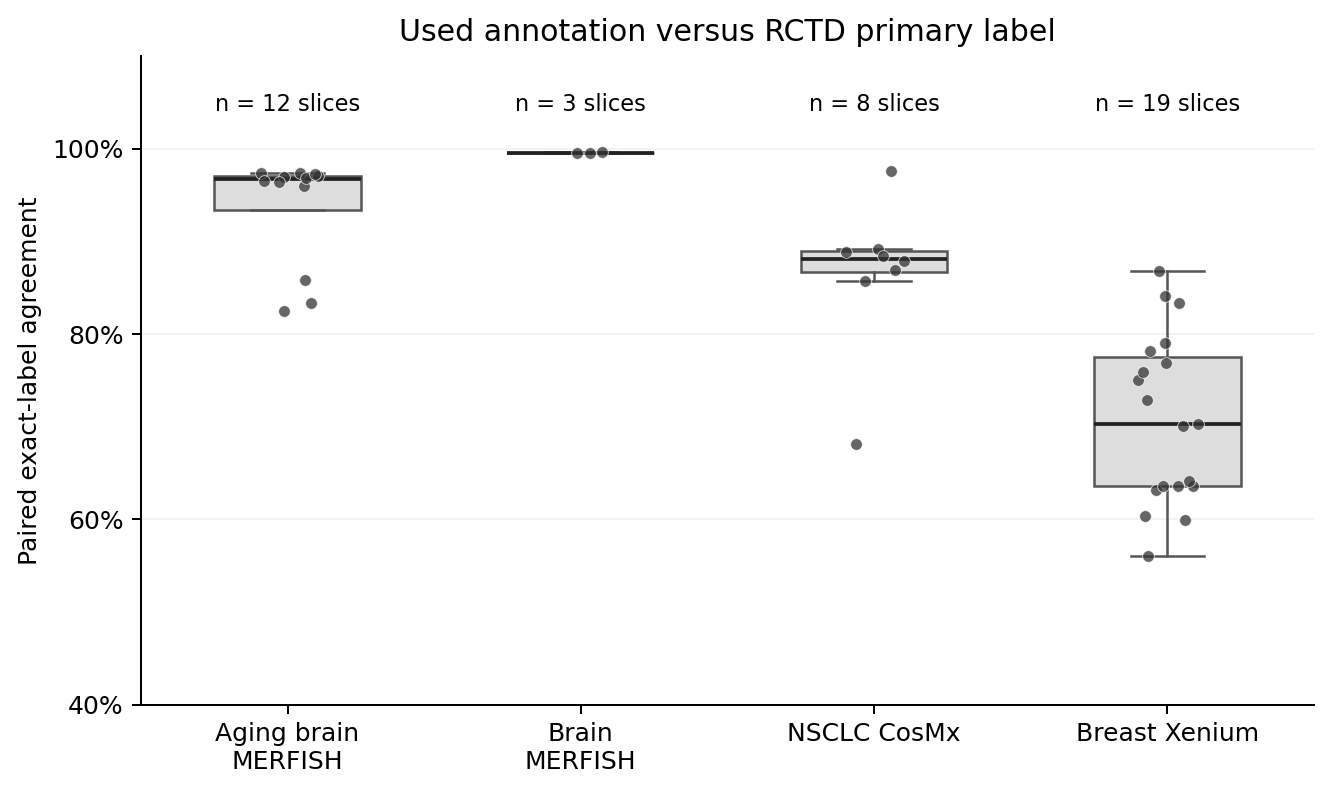

,n_slices,median_agreement,q25,q75,n_agreement_cells
dataset,,,,,
agingbrain_merfish,12,0.966767,0.934056,0.970975,61131
brain_merfish,3,0.995047,0.994993,0.995476,128715
nsclc_cosmx,8,0.881179,0.866593,0.889463,312418
breast_xenium,19,0.703251,0.635778,0.775297,1233787


Saved: /home/jwinchel/Syndri/figures/outputs/SuppFig1_RCTD_20261020_163144_326407/paired_label_agreement_by_dataset_v5


In [4]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Use the current notebook run; the fallback permits running this cell alone.
agreement_output_dir = Path(globals().get("OUTPUT_DIR", "/home/jwinchel/Syndri/figures/outputs/SuppFig1_RCTD_20261020_163144_326407"))
agreement_data = coverage.copy() if "coverage" in globals() else pd.read_csv(agreement_output_dir / "slice_coverage.csv")
agreement_config = DATASETS if "DATASETS" in globals() else json.loads((agreement_output_dir / "dataset_config.json").read_text())
agreement_order = list(agreement_config)
agreement_data["n_agreement_cells"] = agreement_data.n_paired_singlets - agreement_data.n_singlets_missing_either_label
agreement_data = agreement_data.loc[agreement_data.n_agreement_cells.gt(0) & agreement_data.paired_label_agreement.notna()].copy()
if agreement_data.empty:
    raise ValueError("No slices have paired labels for agreement")
assert agreement_data.paired_label_agreement.between(0, 1).all()
fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=180)
values = [agreement_data.loc[agreement_data.dataset.eq(ds), "paired_label_agreement"].to_numpy() for ds in agreement_order]
box = ax.boxplot(values, positions=np.arange(len(agreement_order)), widths=.50,
                 patch_artist=True, showfliers=False,
                 medianprops={"color":"#222222", "linewidth":1.5},
                 boxprops={"facecolor":"#dddddd", "edgecolor":"#555555"},
                 whiskerprops={"color":"#555555"}, capprops={"color":"#555555"})
rng = np.random.default_rng(42)
for xpos, vals in enumerate(values):
    ax.scatter(xpos + rng.uniform(-.11, .11, len(vals)), vals,
               color="#333333", s=22, alpha=.75, edgecolor="white", linewidth=.35, zorder=3)
    ax.text(xpos, 1.035, f"n = {len(vals)} slices", ha="center", va="bottom", fontsize=9)
ax.set_xticks(np.arange(len(agreement_order)), [agreement_config[ds]["title"].replace(" MERFISH", "\nMERFISH") for ds in agreement_order])
# ax.set_ylim(0, 1.10)
ax.set_yticks(np.linspace(0, 1, 6))
ax.set_ylim(0.4, 1.10)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Paired exact-label agreement")
ax.set_title("Used annotation versus RCTD primary label")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=.15)
fig.tight_layout()
agreement_stem = agreement_output_dir / "paired_label_agreement_by_dataset"
version = 1
while any(agreement_stem.with_suffix(ext).exists() for ext in [".png", ".pdf", ".csv"]):
    version += 1
    agreement_stem = agreement_output_dir / f"paired_label_agreement_by_dataset_v{version}"
for ext in [".png", ".pdf"]:
    fig.savefig(agreement_stem.with_suffix(ext), bbox_inches="tight")
agreement_data.to_csv(agreement_stem.with_suffix(".csv"), index=False)
plt.show()
agreement_summary = agreement_data.groupby("dataset", sort=False).agg(
    n_slices=("slice", "nunique"), median_agreement=("paired_label_agreement", "median"),
    q25=("paired_label_agreement", lambda s:s.quantile(.25)),
    q75=("paired_label_agreement", lambda s:s.quantile(.75)),
    n_agreement_cells=("n_agreement_cells", "sum"))
display(agreement_summary)
print("Saved:", agreement_stem)
